## Variational AutoEncoders

+ 在上一节中，我们探讨了简单的自编码器（AutoEncoder）如何在更低维的潜在空间中学习输入数据的高效表征。自编码器能够忠实地对任何样本进行编码，并在之后恢复（或解码）它。这对于特征提取或数据表示而言效果很好，但不太适合用来生成新的样本。
+ 变分自编码器（Variational AutoEncoder，VAE）通过为潜在空间中的每个特征学习一个概率分布来解决这一问题。VAE 并不是将输入映射到具体的点，而是用高斯分布来表示每个特征，从而捕捉该特征在数据中的变异性。

In [1]:
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from matplotlib import pyplot as plt
from PIL import Image
from torch import nn, optim
from torch.utils.data import DataLoader, Dataset
from torchmetrics.image import StructuralSimilarityIndexMeasure
from torchvision.transforms import Compose, Resize, ToTensor
from train_cuda import train

In [2]:
class ImageFile(Dataset):
    def __init__(self, image_path, transform=None):
        self.image_path = Path(image_path)
        self.transform = transform
        image_extensions = ("*.jpg", "*.jpeg", "*.png", "*.gif")
        self.image_files = [
            file for ext in image_extensions for file in self.image_path.glob(ext)
        ]

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        image_file = self.image_files[idx]
        image = Image.open(image_file).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, image

In [3]:
transform = Compose(
    [
        Resize((64, 64)),
        ToTensor(),
        lambda x: 2 * x - 1  # [0,1] → [-1,1]，匹配tanh 
    ]
)
image_path = "./Datasets/images"

In [4]:
ImageDataset = ImageFile(image_path=image_path, transform=transform)
train_loader = DataLoader(ImageDataset, batch_size=256, shuffle=True)

In [5]:
class Encoder(nn.Module):
    def __init__(self, in_channels=3):
        super().__init__()
        self.con_block = nn.Sequential(
            # 3@64x64 -> 64@32x32
            nn.Conv2d(in_channels, 64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.BatchNorm2d(64),
            # 64@32x32 -> 128@16x16
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.BatchNorm2d(128),
            # 128@16x16 -> 256@8x8
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.BatchNorm2d(256),
            # 256@8x8 -> 512@4x4
            nn.Conv2d(256, 512, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.BatchNorm2d(512),
            # 512@4x4 -> 1024@1x1
            nn.Conv2d(512, 1024, kernel_size=4, stride=2, padding=0),
            nn.LeakyReLU(0.2),
            nn.BatchNorm2d(1024),
        )
        self.fc_block = nn.Sequential(
            nn.Linear(1024, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
        )

    def forward(self, x):
        x = self.con_block(x)
        # shape: (batch_size, 1024, 1, 1)
        x = x.flatten(start_dim=1)
        # shape: (batch_size, 1024)
        mu = self.fc_block(x)
        logvar = self.fc_block(x)
        return mu, logvar

In [6]:
class Decoder(nn.Module):
    def __init__(self, out_channels=3):
        super().__init__()
        self.fc_block = nn.Sequential(
            # shape: (batch_size, 256) -> (batch_size, 512)
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            # shape: (batch_size, 512) -> (batch_size, 1024)
            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2),
        )
        self.con_block = nn.Sequential(
            # 1024@1x1 -> 512@4x4
            nn.ConvTranspose2d(1024, 512, kernel_size=4, stride=1, padding=0),
            nn.LeakyReLU(0.2),
            nn.BatchNorm2d(512),
            # 512@4x4 -> 256@8x8
            nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.BatchNorm2d(256),
            # 256@8x8 -> 128@16x16
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.BatchNorm2d(128),
            # 128@16x16 -> 64@32x32
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.BatchNorm2d(64),
            # 64@32x32 -> 3@64x64
            nn.ConvTranspose2d(64, out_channels, kernel_size=4, stride=2, padding=1),
        )

    def forward(self, x):
        x = self.fc_block(x)
        # shape: (batch_size, 1024)
        x = x.view(-1, 1024, 1, 1)
        # shape: (batch_size, 1024, 1, 1)
        x = self.con_block(x)
        # shape: (batch_size, out_channels, 64, 64)
        return F.tanh(x)


In [7]:
class AutoEncoder(nn.Module):
    def __init__(self, in_channels=3, out_channels=3):
        super().__init__()
        self.encoder = Encoder(in_channels=in_channels)
        self.decoder = Decoder(out_channels=out_channels)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, logvar = self.encoder(x)
        x = self.reparameterize(mu, logvar) 
        x = self.decoder(x)
        return x

In [8]:
class SSIM_MSE_Loss(nn.Module):
    def __init__(self, ssim_weight=0.3, mse_weight=0.7):
        super().__init__()
        self.ssim = StructuralSimilarityIndexMeasure(data_range=1.0)
        self.MSE = nn.MSELoss()
        self.ssim_weight = ssim_weight
        self.mse_weight = mse_weight

    def forward(self, x, y):
        ssim_loss = 1 - self.ssim(x, y)
        mse_loss = self.MSE(x, y)
        return self.ssim_weight * ssim_loss + self.mse_weight * mse_loss

In [9]:
device = "cuda" if torch.cuda.is_available() else "cpu"
epochs = 50
lr = 1e-3
model = AutoEncoder(in_channels=3, out_channels=3).to(device)
optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
loss_fn = SSIM_MSE_Loss().to(device)


In [10]:
train_losses, _ = train(
    model, train_loader, None, loss_fn, optimizer, epochs, device=device
)

Epoch 1/50 - loss: 0.4079
Epoch 2/50 - loss: 0.3563
Epoch 3/50 - loss: 0.3283
Epoch 4/50 - loss: 0.3123
Epoch 5/50 - loss: 0.3019
Epoch 6/50 - loss: 0.2922
Epoch 7/50 - loss: 0.2842
Epoch 8/50 - loss: 0.2755
Epoch 9/50 - loss: 0.2677
Epoch 10/50 - loss: 0.2610
Epoch 11/50 - loss: 0.2553
Epoch 12/50 - loss: 0.2501
Epoch 13/50 - loss: 0.2450
Epoch 14/50 - loss: 0.2405
Epoch 15/50 - loss: 0.2365
Epoch 16/50 - loss: 0.2327
Epoch 17/50 - loss: 0.2287
Epoch 18/50 - loss: 0.2250
Epoch 19/50 - loss: 0.2213
Epoch 20/50 - loss: 0.2175
Epoch 21/50 - loss: 0.2145
Epoch 22/50 - loss: 0.2108
Epoch 23/50 - loss: 0.2081
Epoch 24/50 - loss: 0.2048
Epoch 25/50 - loss: 0.2022
Epoch 26/50 - loss: 0.1986
Epoch 27/50 - loss: 0.1960
Epoch 28/50 - loss: 0.1937
Epoch 29/50 - loss: 0.1909
Epoch 30/50 - loss: 0.1885
Epoch 31/50 - loss: 0.1862
Epoch 32/50 - loss: 0.1844
Epoch 33/50 - loss: 0.1826
Epoch 34/50 - loss: 0.1803
Epoch 35/50 - loss: 0.1786
Epoch 36/50 - loss: 0.1767
Epoch 37/50 - loss: 0.1745
Epoch 38/5

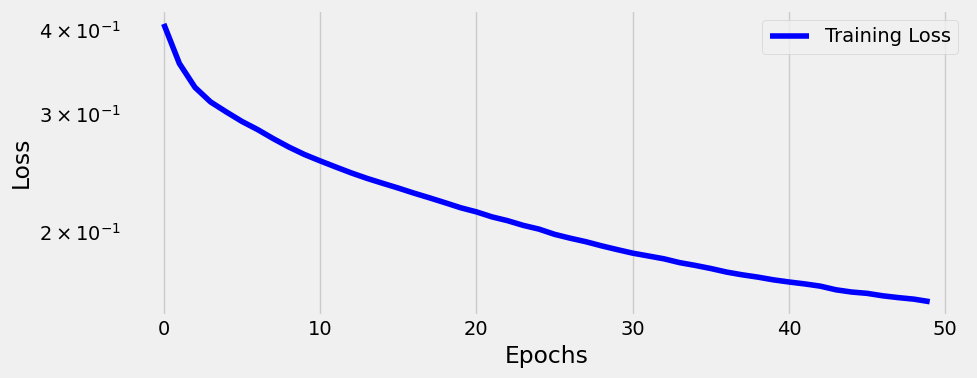

In [11]:
plt.style.use("fivethirtyeight")
def plot_losses():
    fig = plt.figure(figsize=(10, 4))
    plt.plot(train_losses, label="Training Loss", c="b")
    plt.yscale("log")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    return fig


fig = plot_losses()

In [12]:
fake_image = torch.randn(10, 256).to(device)
with torch.inference_mode():
    reconstructed_image = model.decoder(fake_image)
images = reconstructed_image.detach().cpu().permute(0, 2, 3, 1).numpy()

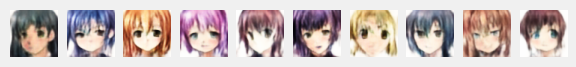

In [14]:
fig, ax = plt.subplots(1, 10)
for i in range(10):
    ax[i].imshow((images[i] + 1) / 2)
    ax[i].axis("off")


In [15]:
torch.save(model.state_dict(), "./Datasets/vae_encoder.pth")